In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import json
from pathlib import Path


In [2]:
# source_path = Path(
#     "/Users/jolin/Documents/Yelp-Reviews-/Yelp JSON/yelp_dataset "
#     "/yelp_academic_dataset_user.json"
# )
# clean_path = source_path.with_name("yelp_academic_dataset_user_clean.json")

# bad_lines = []

# with source_path.open("r", encoding="utf-8") as source, \
#      clean_path.open("w", encoding="utf-8") as clean:
#     for line_number, line in enumerate(source, start=1):
#         try:
#             json.loads(line)
#         except json.JSONDecodeError:
#             bad_lines.append(line_number)
#             continue
#         clean.write(line)

# print(f"Skipped {len(bad_lines)} malformed records: {bad_lines[:10]}")

# chunks = pd.read_json(clean_path, lines=True, chunksize=50_000)
# user = pd.concat(chunks, ignore_index=True)

# print(user.shape)

In [3]:
review = pd.concat(
    pd.read_json(
        '/Users/jolin/Documents/Yelp-Reviews-/Yelp JSON/yelp_dataset /yelp_academic_dataset_review.json',
        lines=True,
        chunksize=50_000,
    ),
    ignore_index=True,
)
checkin = pd.read_json('/Users/jolin/Documents/Yelp-Reviews-/Yelp JSON/yelp_dataset /yelp_academic_dataset_checkin.json', lines=True)
business = pd.read_json('/Users/jolin/Documents/Yelp-Reviews-/Yelp JSON/yelp_dataset /yelp_academic_dataset_business.json', lines=True)
tip = pd.read_json('/Users/jolin/Documents/Yelp-Reviews-/Yelp JSON/yelp_dataset /yelp_academic_dataset_tip.json', lines=True)
photos = pd.read_json('/Users/jolin/Documents/Yelp-Reviews-/Yelp Photos/yelp_photos/photos.json', lines=True)

embeddings = np.load('/Users/jolin/Documents/Yelp-Reviews-/yelp_business_level_embeddings.npz', allow_pickle=True)

In [4]:
tip.head()

,user_id,business_id,text,date,compliment_count
0,AGNUgVwnZUey3gcPCJ76iw,3uLgwr0qeCNMjKenHJwPGQ,Avengers time with the ladies.,2012-05-18 02:17:21,0
1,NBN4MgHP9D3cw--SnauTkA,QoezRbYQncpRqyrLH6Iqjg,They have lots of good deserts and tasty cuban...,2013-02-05 18:35:10,0
2,-copOvldyKh1qr-vzkDEvw,MYoRNLb5chwjQe3c_k37Gg,It's open even when you think it isn't,2013-08-18 00:56:08,0
3,FjMQVZjSqY8syIO-53KFKw,hV-bABTK-glh5wj31ps_Jw,Very decent fried chicken,2017-06-27 23:05:38,0
4,ld0AperBXk1h6UbqmM80zw,_uN0OudeJ3Zl_tf6nxg5ww,Appetizers.. platter special for lunch,2012-10-06 19:43:09,0


In [5]:
review.head()

,review_id,user_id,business_id,stars,useful,funny,cool,text,date
0,KU_O5udG6zpxOg-VcAEodg,mh_-eMZ6K5RLWhZyISBhwA,XQfwVwDr-v0ZS3_CbbE5Xw,3,0,0,0,"If you decide to eat here, just be aware it is...",2018-07-07 22:09:11
1,BiTunyQ73aT9WBnpR9DZGw,OyoGAe7OKpv6SyGZT5g77Q,7ATYjTIgM3jUlt4UM3IypQ,5,1,0,1,I've taken a lot of spin classes over the year...,2012-01-03 15:28:18
2,saUsX_uimxRlCVr67Z4Jig,8g_iMtfSiwikVnbP2etR0A,YjUWPpI6HXG530lwP-fb2A,3,0,0,0,Family diner. Had the buffet. Eclectic assortm...,2014-02-05 20:30:30
3,AqPFMleE6RsU23_auESxiA,_7bHUi9Uuf5__HHc_Q8guQ,kxX2SOes4o-D3ZQBkiMRfA,5,1,0,1,"Wow! Yummy, different, delicious. Our favo...",2015-01-04 00:01:03
4,Sx8TMOWLNuJBWer-0pcmoA,bcjbaE6dDog4jkNY91ncLQ,e4Vwtrqf-wpJfwesgvdgxQ,4,1,0,1,Cute interior and owner (?) gave us tour of up...,2017-01-14 20:54:15


In [6]:
checkin.head()

,business_id,date
0,---kPU91CF4Lq2-WlRu9Lw,"2020-03-13 21:10:56, 2020-06-02 22:18:06, 2020..."
1,--0iUa4sNDFiZFrAdIWhZQ,"2010-09-13 21:43:09, 2011-05-04 23:08:15, 2011..."
2,--30_8IhuyMHbSOcNWd6DQ,"2013-06-14 23:29:17, 2014-08-13 23:20:22"
3,--7PUidqRWpRSpXebiyxTg,"2011-02-15 17:12:00, 2011-07-28 02:46:10, 2012..."
4,--7jw19RH9JKXgFohspgQw,"2014-04-21 20:42:11, 2014-04-28 21:04:46, 2014..."


In [7]:
business.head()

,business_id,name,address,city,state,postal_code,latitude,longitude,stars,review_count,is_open,attributes,categories,hours
0,Pns2l4eNsfO8kk83dixA6A,"Abby Rappoport, LAC, CMQ","1616 Chapala St, Ste 2",Santa Barbara,CA,93101,34.426679,-119.711197,5.0,7,0,{'ByAppointmentOnly': 'True'},"Doctors, Traditional Chinese Medicine, Naturop...",None
1,mpf3x-BjTdTEA3yCZrAYPw,The UPS Store,87 Grasso Plaza Shopping Center,Affton,MO,63123,38.551126,-90.335695,3.0,15,1,{'BusinessAcceptsCreditCards': 'True'},"Shipping Centers, Local Services, Notaries, Ma...","{'Monday': '0:0-0:0', 'Tuesday': '8:0-18:30', ..."
2,tUFrWirKiKi_TAnsVWINQQ,Target,5255 E Broadway Blvd,Tucson,AZ,85711,32.223236,-110.880452,3.5,22,0,"{'BikeParking': 'True', 'BusinessAcceptsCredit...","Department Stores, Shopping, Fashion, Home & G...","{'Monday': '8:0-22:0', 'Tuesday': '8:0-22:0', ..."
3,MTSW4McQd7CbVtyjqoe9mw,St Honore Pastries,935 Race St,Philadelphia,PA,19107,39.955505,-75.155564,4.0,80,1,"{'RestaurantsDelivery': 'False', 'OutdoorSeati...","Restaurants, Food, Bubble Tea, Coffee & Tea, B...","{'Monday': '7:0-20:0', 'Tuesday': '7:0-20:0', ..."
4,mWMc6_wTdE0EUBKIGXDVfA,Perkiomen Valley Brewery,101 Walnut St,Green Lane,PA,18054,40.338183,-75.471659,4.5,13,1,"{'BusinessAcceptsCreditCards': 'True', 'Wheelc...","Brewpubs, Breweries, Food","{'Wednesday': '14:0-22:0', 'Thursday': '16:0-2..."


In [8]:
embeddings.keys()

KeysView(NpzFile '/Users/jolin/Documents/Yelp-Reviews-/yelp_business_level_embeddings.npz' with keys: photo_ids, photo_business_ids, image_embeddings, business_ids, business_text_embeddings)

In [9]:
photo_ids = embeddings['photo_ids']
photo_business_ids = embeddings['photo_business_ids']
image_embeddings = embeddings['image_embeddings']

business_ids = embeddings['business_ids']
business_text_embeddings = embeddings['business_text_embeddings']

In [10]:
image_embeddings[0].shape

(768,)

Filtering business categories...
Selecting and aggregating restaurant photo embeddings...
Fitting PCA on 29,374 restaurants and 1,152 features (30 components)...


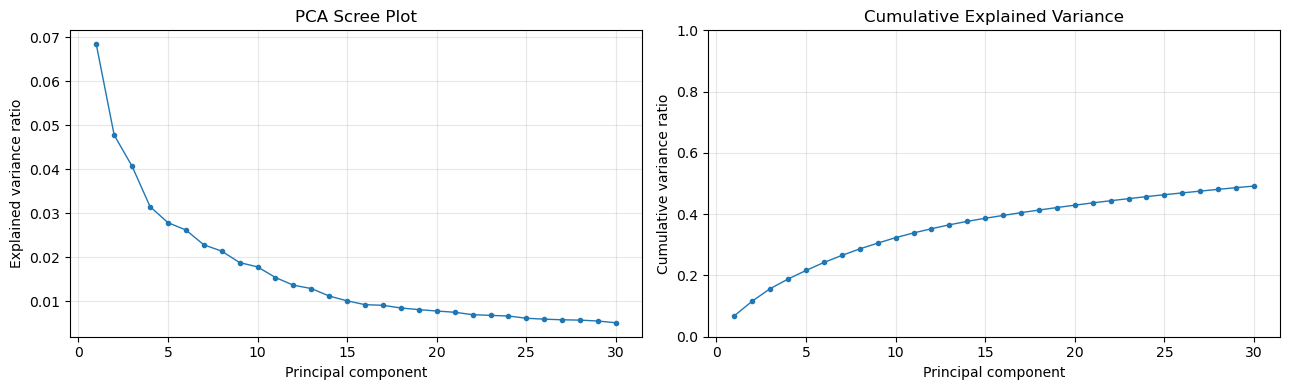

Fitting K-means...
Restaurants with matching image and text embeddings: 29,374
PCA components used for clustering: 15
K-means clusters: 11
K-means inertia: 6008.30


,business_id,cluster
0,--epgcb7xHGuJ-4PUeSLAw,3
1,--hF_3v1JmU9nlu4zfXJ8Q,1
2,--onnLZrsCazmcy2P_7fcw,4
3,-09Oc2D14vRnmirPh0vlXw,8
4,-0FX23yAacC4bbLaGPvyxw,2


In [11]:
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.preprocessing import normalize

# Tune these independently.
k_pca = 15
k_means = 11

# Keep businesses with the exact Yelp category "Restaurants".
print("Filtering business categories...", flush=True)
is_restaurant = business["categories"].fillna("").str.contains(
    r"(?:^|,\s*)Restaurants(?:\s*,|$)",
    regex=True,
)
restaurant_business_ids = business.loc[is_restaurant, "business_id"]
restaurant_text_mask = pd.Index(business_ids).isin(restaurant_business_ids)
restaurant_text_ids = business_ids[restaurant_text_mask]
restaurant_text_embeddings = business_text_embeddings[restaurant_text_mask]

# Only aggregate photos for businesses that passed the restaurant filter.
print("Selecting and aggregating restaurant photo embeddings...", flush=True)
restaurant_photo_mask = pd.Index(photo_business_ids).isin(restaurant_business_ids)
restaurant_photo_business_ids = photo_business_ids[restaurant_photo_mask]
restaurant_image_embeddings = image_embeddings[restaurant_photo_mask]
image_business_ids, photo_group = np.unique(
    restaurant_photo_business_ids,
    return_inverse=True,
)
image_sums = np.zeros(
    (len(image_business_ids), restaurant_image_embeddings.shape[1]),
    dtype=np.float32,
)
np.add.at(image_sums, photo_group, restaurant_image_embeddings)
image_counts = np.bincount(photo_group)
image_business_embeddings = image_sums / image_counts[:, None]

text_row_by_business_id = {
    business_id: row for row, business_id in enumerate(restaurant_text_ids)
}
image_text_rows = np.array(
    [text_row_by_business_id.get(business_id, -1) for business_id in image_business_ids]
)
has_matching_text = image_text_rows >= 0
business_ids_with_images = image_business_ids[has_matching_text]
image_business_embeddings = image_business_embeddings[has_matching_text]
text_embeddings_for_images = restaurant_text_embeddings[image_text_rows[has_matching_text]]

# Normalize each modality so neither dominates because of its vector magnitude.
combined_embeddings = np.hstack((
    normalize(image_business_embeddings),
    normalize(text_embeddings_for_images),
)).astype(np.float32, copy=False)

max_pca_components = min(combined_embeddings.shape)
if not 1 <= k_pca <= max_pca_components:
    raise ValueError(f"k_pca must be between 1 and {max_pca_components}.")
if not 1 <= k_means <= len(combined_embeddings):
    raise ValueError(f"k_means must be between 1 and {len(combined_embeddings)}.")

# Limit scree computation while retaining every component used for clustering.
n_scree_components = min(max(k_pca, 30), max_pca_components)
print(
    f"Fitting PCA on {combined_embeddings.shape[0]:,} restaurants and "
    f"{combined_embeddings.shape[1]:,} features ({n_scree_components} components)...",
    flush=True,
)
pca = PCA(
    n_components=n_scree_components,
    svd_solver="randomized",
    iterated_power=3,
    random_state=42,
)
pca_coordinates = pca.fit_transform(combined_embeddings)
pca_for_clustering = pca_coordinates[:, :k_pca]

component_numbers = np.arange(1, n_scree_components + 1)
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].plot(component_numbers, pca.explained_variance_ratio_, marker=".", linewidth=1)
axes[0].set(title="PCA Scree Plot", xlabel="Principal component", ylabel="Explained variance ratio")
axes[1].plot(component_numbers, np.cumsum(pca.explained_variance_ratio_), marker=".", linewidth=1)
axes[1].set(title="Cumulative Explained Variance", xlabel="Principal component", ylabel="Cumulative variance ratio")
axes[1].set_ylim(0, 1)
for axis in axes:
    axis.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

print("Fitting K-means...", flush=True)
kmeans = KMeans(n_clusters=k_means, n_init=10, random_state=42)
cluster_labels = kmeans.fit_predict(pca_for_clustering)
business_clusters = pd.DataFrame({
    "business_id": business_ids_with_images,
    "cluster": cluster_labels,
})

print(f"Restaurants with matching image and text embeddings: {len(business_clusters):,}")
print(f"PCA components used for clustering: {k_pca}")
print(f"K-means clusters: {k_means}")
print(f"K-means inertia: {kmeans.inertia_:.2f}")
business_clusters.head()

/opt/anaconda3/envs/iaa/lib/python3.14/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


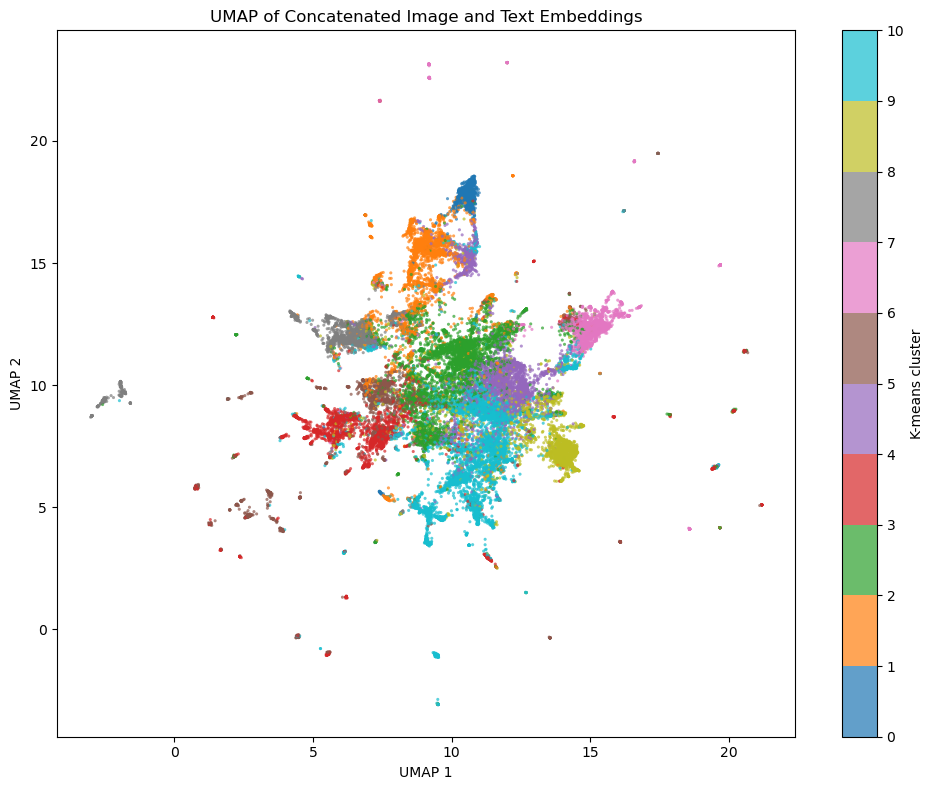

In [18]:
import umap

umap_model = umap.UMAP(
    n_components=2,
    n_neighbors=15,
    min_dist=0.1,
    metric="cosine",
    random_state=42,
)
umap_coordinates = umap_model.fit_transform(combined_embeddings)

plt.figure(figsize=(10, 8))
cluster_plot = plt.scatter(
    umap_coordinates[:, 0],
    umap_coordinates[:, 1],
    c=cluster_labels,
    cmap="tab10",
    s=5,
    alpha=0.7,
    linewidths=0,
)
plt.colorbar(cluster_plot, ticks=np.arange(k_means), label="K-means cluster")
plt.title("UMAP of Concatenated Image and Text Embeddings")
plt.xlabel("UMAP 1")
plt.ylabel("UMAP 2")
plt.tight_layout()
plt.show()

In [16]:
business_columns = [
    "business_id", "name", "city", "state", "stars", "review_count", "is_open", "categories"
]
cluster_businesses = business_clusters.merge(
    business[business_columns],
    on="business_id",
    how="left",
    validate="one_to_one",
)

cluster_profile = cluster_businesses.groupby("cluster").agg(
    businesses=("business_id", "size"),
    mean_stars=("stars", "mean"),
    median_review_count=("review_count", "median"),
    open_share=("is_open", "mean"),
).round(2)
display(cluster_profile)

category_rows = (
    cluster_businesses.dropna(subset=["categories"])
    .assign(category=lambda frame: frame["categories"].str.split(","))
    .explode("category")
)
category_rows["category"] = category_rows["category"].str.strip()
category_summary = (
    category_rows.groupby(["cluster", "category"])
    .size()
    .rename("businesses")
    .reset_index()
    .merge(
        cluster_profile[["businesses"]].rename(columns={"businesses": "cluster_size"}),
        left_on="cluster",
        right_index=True,
    )
)
category_summary["pct_cluster"] = (
    100 * category_summary["businesses"] / category_summary["cluster_size"]
).round(1)
top_categories = (
    category_summary.sort_values(["cluster", "businesses"], ascending=[True, False])
    .groupby("cluster")
    .head(8)
    .drop(columns="cluster_size")
)
display(top_categories)

# Show businesses nearest each K-means centroid in the PCA space used for clustering.
centroid_distances = kmeans.transform(pca_for_clustering)
representative_rows = []
for cluster_id in range(k_means):
    member_rows = np.flatnonzero(cluster_labels == cluster_id)
    nearest_rows = member_rows[
        np.argsort(centroid_distances[member_rows, cluster_id])[:5]
    ]
    representative_rows.extend(nearest_rows)

representative_businesses = cluster_businesses.iloc[representative_rows][
    ["cluster", "name", "city", "state", "categories", "stars", "review_count"]
]
display(representative_businesses.sort_values(["cluster", "stars"], ascending=[True, False]))

,businesses,mean_stars,median_review_count,open_share
cluster,,,,
0,1012,3.86,113.5,0.75
1,3218,3.87,62.0,0.72
2,4918,3.77,114.0,0.72
3,2687,3.44,41.0,0.77
4,3077,3.77,94.0,0.67
5,2172,2.79,31.5,0.83
6,1749,3.27,41.0,0.79
7,1973,3.40,46.0,0.80
8,2585,3.67,48.0,0.70


,cluster,category,businesses,pct_cluster
89,0,Restaurants,1012,100.0
103,0,Sushi Bars,848,83.8
62,0,Japanese,734,72.5
5,0,Asian Fusion,261,25.8
44,0,Food,159,15.7
...,...,...,...,...
2397,10,Bars,1457,36.9
2376,10,American (Traditional),931,23.6
2375,10,American (New),753,19.1
2637,10,Sandwiches,697,17.7


,cluster,name,city,state,categories,stars,review_count
5403,0,Sushi House,Tampa,FL,"Sushi Bars, Salad, Restaurants, Japanese",4.5,212
4291,0,Fuji Sushi,Metairie,LA,"Restaurants, Sushi Bars",4.0,154
17753,0,Saki Endless Sushi & Hibachi Eatery,Clearwater,FL,"Restaurants, Salad, Sushi Bars, Soup, Japanese",3.5,473
7245,0,Sushi GoGo,Santa Barbara,CA,"Sushi Bars, Japanese, Restaurants",3.5,178
14131,0,Fat tuna,Philadelphia,PA,"Bubble Tea, Juice Bars & Smoothies, Coffee & T...",3.5,25
2512,1,Songkran Thai Restaurant,St. Albert,AB,"Thai, Restaurants",4.0,34
28417,1,Angkorians,Nashville,TN,"Restaurants, Cambodian",4.0,25
26382,1,India Rasoi,Saint Louis,MO,"Buffets, Vegetarian, Restaurants, Pakistani, I...",4.0,340
10842,1,Hong Kong Restaurant,Mooresville,IN,"Chinese, Restaurants, Asian Fusion",4.0,28
19955,1,Mama Lu,Santa Barbara,CA,"Asian Fusion, Chinese, Restaurants",3.0,45


In [14]:
# # check outliers
# centroid_distances = kmeans.transform(pca_for_clustering)
# assigned_distances = centroid_distances[
#     np.arange(len(cluster_labels)), cluster_labels
# ]
# cutoff = np.quantile(assigned_distances, 0.99)

# outlier_candidates = cluster_businesses.assign(
#     umap_1=umap_coordinates[:, 0],
#     umap_2=umap_coordinates[:, 1],
#     centroid_distance=assigned_distances,
# )
# outlier_candidates = outlier_candidates[
#     outlier_candidates["centroid_distance"] >= cutoff
# ].sort_values("centroid_distance", ascending=False)

# display(outlier_candidates[
#     ["name", "city", "categories", "cluster", "centroid_distance", "umap_1", "umap_2"]
# ].head(50))

In [19]:
cluster_names = {
    0: "Sushi and Japanese",
    1: "Pan-Asian dining, Chinese-led",
    2: "American dining and nightlife",
    3: "Sandwiches, delis, and fast-casual",
    4: "Regional and full-service casual dining",
    5: "Fast-food burgers and chicken",
    6: "Pizza and Italian",
    7: "Mexican and Tex-Mex",
    8: "Eclectic cafes, brunch, and comfort food",
    9: "Coffee, bakeries, and desserts",
    10: "Pubs, bars, and bar-forward dining",
}

business_clusters["cluster_name"] = business_clusters["cluster"].map(cluster_names)
cluster_businesses["cluster_name"] = cluster_businesses["cluster"].map(cluster_names)
representative_businesses["cluster_name"] = representative_businesses["cluster"].map(cluster_names)

cluster_label_summary = cluster_profile.copy()
cluster_label_summary.insert(
    0,
    "cluster_name",
    cluster_label_summary.index.map(cluster_names),
)
display(cluster_label_summary)

for cluster_id, cluster_rows in top_categories.groupby("cluster", sort=True):
    category_labels = ", ".join(
        f"{row.category} ({row.pct_cluster:.0f}%)"
        for row in cluster_rows.sort_values("businesses", ascending=False).head(5).itertuples()
    )
    print(f"Cluster {cluster_id}: {cluster_names[cluster_id]} | {category_labels}")

,cluster_name,businesses,mean_stars,median_review_count,open_share
cluster,,,,,
0,Sushi and Japanese,1012,3.86,113.5,0.75
1,"Pan-Asian dining, Chinese-led",3218,3.87,62.0,0.72
2,American dining and nightlife,4918,3.77,114.0,0.72
3,"Sandwiches, delis, and fast-casual",2687,3.44,41.0,0.77
4,Regional and full-service casual dining,3077,3.77,94.0,0.67
5,Fast-food burgers and chicken,2172,2.79,31.5,0.83
6,Pizza and Italian,1749,3.27,41.0,0.79
7,Mexican and Tex-Mex,1973,3.40,46.0,0.80
8,"Eclectic cafes, brunch, and comfort food",2585,3.67,48.0,0.70


Cluster 0: Sushi and Japanese | Restaurants (100%), Sushi Bars (84%), Japanese (72%), Asian Fusion (26%), Food (16%)
Cluster 1: Pan-Asian dining, Chinese-led | Restaurants (100%), Food (26%), Chinese (24%), Asian Fusion (15%), Seafood (11%)
Cluster 2: American dining and nightlife | Restaurants (100%), Nightlife (38%), Bars (37%), American (New) (31%), American (Traditional) (29%)
Cluster 3: Sandwiches, delis, and fast-casual | Restaurants (100%), Sandwiches (49%), Food (34%), Fast Food (29%), Burgers (29%)
Cluster 4: Regional and full-service casual dining | Restaurants (100%), Nightlife (28%), Bars (27%), Food (24%), American (Traditional) (20%)
Cluster 5: Fast-food burgers and chicken | Restaurants (100%), Fast Food (49%), Burgers (39%), American (Traditional) (37%), Chicken Wings (32%)
Cluster 6: Pizza and Italian | Restaurants (100%), Pizza (97%), Italian (46%), Chicken Wings (28%), Sandwiches (24%)
Cluster 7: Mexican and Tex-Mex | Restaurants (100%), Mexican (74%), Fast Food (34%